Import and configuration

In [1]:
# !pip install ipywidgets

In [2]:
import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical
import matplotlib.pyplot as plt
import pandas as pd
import time
from tqdm.notebook import tqdm
import random

# Assuming your environment files are in the same directory
from manual_kx_env_for_test_4 import GeneratedKXEnv


In [3]:
# --- Hyperparameters for Speed (30 min target) ---
LR = 2e-4
GAMMA = 0.99
GAE_LAMBDA = 0.95
PPO_CLIP = 0.2
PPO_EPOCHS = 4        # Reduced epochs for speed
BATCH_SIZE = 128      # Smaller batches for more frequent updates
ENTROPY_COEF = 0.01
UPDATE_EVERY_STEPS = 2048
TOTAL_TIMESTEPS = 5000 # Roughly 1000-1500 episodes depending on length
MAX_STEPS_PER_EP = 400

Models

In [4]:
class ActorCritic(nn.Module):
    def __init__(self, obs_dim, action_dim):
        super(ActorCritic, self).__init__()
        self.shared = nn.Sequential(
            nn.Linear(obs_dim, 256),
            nn.ReLU(), # ReLU is faster than Tanh for training speed
            nn.Linear(256, 256),
            nn.ReLU()
        )
        self.actor = nn.Linear(256, action_dim)
        self.critic = nn.Linear(256, 1)

    def forward(self, x, mask=None):
        features = self.shared(x)
        logits = self.actor(features)
        if mask is not None:
            logits[~mask] = -1e10
        return logits, self.critic(features)

In [5]:
class FastPPO:
    def __init__(self, env):
        self.env = env
        self.obs_dim = 14 # 8 base + 6 derived
        self.action_dim = 4
        self.model = ActorCritic(self.obs_dim, self.action_dim)
        self.optimizer = optim.Adam(self.model.parameters(), lr=LR)
        self.memory = []

    def normalize_obs(self, obs):
        xr, vr, ar, xg, t, T, GDelta, Vmax = obs
        # Derived features
        dist_start = (xg - GDelta) - xr
        dist_end = (xg + GDelta) - xr
        time_rem = self.env.constants['ep'] - t
        
        norm = np.array([
            xr/200, vr/30, ar/10, xg/200, t/1.0, T/1000, GDelta/100, Vmax/30,
            dist_start/200, dist_end/200, time_rem/0.5,
            1.0 if vr >= (self.env.constants['A']*self.env.constants['ep']) else 0.0,
            1.0 if vr >= Vmax else 0.0,
            1.0 if abs(vr) < 1e-2 else 0.0
        ], dtype=np.float32)
        return norm

    def get_action_mask(self, state_dict):
        mask = torch.zeros(self.action_dim, dtype=torch.bool)
        for i, choice in enumerate(self.env._control_func_action_config.choices):
            if self.env._evaluate_expression(choice.actions[0].formula, local_vars=state_dict, is_constraint=True):
                mask[i] = True
        return mask if torch.any(mask) else torch.ones(self.action_dim, dtype=torch.bool)

    def update(self):
        if len(self.memory) < BATCH_SIZE: return
        
        states = torch.tensor(np.array([m[0] for m in self.memory]))
        actions = torch.tensor([m[1] for m in self.memory])
        old_log_probs = torch.tensor([m[2] for m in self.memory])
        rewards = torch.tensor([m[3] for m in self.memory])
        masks = torch.tensor([m[4] for m in self.memory])
        values = torch.tensor([m[5] for m in self.memory])
        action_masks = torch.stack([m[6] for m in self.memory])

        # GAE
        returns = []
        gae = 0
        for i in reversed(range(len(rewards))):
            next_value = values[i+1] if i+1 < len(values) else 0
            delta = rewards[i] + GAMMA * next_value * masks[i] - values[i]
            gae = delta + GAMMA * GAE_LAMBDA * masks[i] * gae
            returns.insert(0, gae + values[i])
        returns = torch.tensor(returns)
        advantages = returns - values
        advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

        for _ in range(PPO_EPOCHS):
            logits, val = self.model(states, action_masks)
            dist = Categorical(logits=logits)
            new_log_probs = dist.log_prob(actions)
            entropy = dist.entropy().mean()
            
            ratio = torch.exp(new_log_probs - old_log_probs)
            surr1 = ratio * advantages
            surr2 = torch.clamp(ratio, 1.0 - PPO_CLIP, 1.0 + PPO_CLIP) * advantages
            
            loss = -torch.min(surr1, surr2).mean() + 0.5 * nn.MSELoss()(val.squeeze(), returns) - ENTROPY_COEF * entropy
            
            self.optimizer.zero_grad()
            loss.backward()
            self.optimizer.step()
        self.memory = []

Training

In [6]:
env = GeneratedKXEnv(debug_mode=False)
agent = FastPPO(env)

stats = {'rewards': [], 'success_rate': []}
global_step = 0
success_history = []

pbar = tqdm(total=TOTAL_TIMESTEPS, desc="Training Agent")
while global_step < TOTAL_TIMESTEPS:
    obs, info = env.reset()
    done = False
    ep_reward = 0
    
    for _ in range(MAX_STEPS_PER_EP):
        norm_obs = agent.normalize_obs(obs)
        act_mask = agent.get_action_mask(env.state)
        
        with torch.no_grad():
            logits, val = agent.model(torch.FloatTensor(norm_obs).unsqueeze(0), act_mask.unsqueeze(0))
            dist = Categorical(logits=logits)
            action = dist.sample()
            log_prob = dist.log_prob(action)
        
        next_obs, reward, term, trunc, info = env.step({'choice_ChoiceLevel_0': action.item()})
        
        # Reward Shaping: Focus on distance reduction
        shaped_reward = reward / 100.0
        dist_to_goal = (obs[3] - obs[6]) - obs[0]
        next_dist_to_goal = (next_obs[3] - next_obs[6]) - next_obs[0]
        shaped_reward += (dist_to_goal - next_dist_to_goal) * 5.0 # High incentive to move
        
        agent.memory.append((norm_obs, action, log_prob, shaped_reward, 1.0 - term, val.item(), act_mask))
        
        obs = next_obs
        ep_reward += shaped_reward
        global_step += 1
        pbar.update(1)
        
        if term or trunc:
            success_history.append(1 if info.get('termination_status') == 'success' else 0)
            break
            
        if global_step % UPDATE_EVERY_STEPS == 0:
            agent.update()
            
    stats['rewards'].append(ep_reward)
    if len(success_history) >= 100:
        stats['success_rate'].append(np.mean(success_history[-100:]))

torch.save(agent.model.state_dict(), "fast_ppo_model.pth")
print("Training Complete!")

DEBUG_CISB: Expanding KeYmaera X expression for Z3 conversion: assumptions(xr, vr, ar, xg, t, T)
DEBUG_CISB: Expanded KeYmaera X expression: ((((((A > 0) & (b > 0)) & (ep > 0)) & (Vmax >= ((2 * A) * ep))) & (GDelta > ((Vmax * ep) + ((Vmax ^ 2) / (2 * b))))) & (((((vr = 0) & (ar = 0)) & (t = 0)) & (xr < (xg - GDelta))) & (T > (((ep + (((xg - xr) - GDelta) / (A * ep))) + ep) + (Vmax / b)))))


Training Agent:   0%|          | 0/5000 [00:00<?, ?it/s]

Training Complete!


Evaluation

In [7]:
def evaluate_and_analyze(agent, env, num_episodes=50):
    agent.model.eval()
    results = []
    
    print(f"Running Evaluation on {num_episodes} samples...")
    for i in range(num_episodes):
        obs, info = env.reset()
        initial_state = env.state.copy()
        done = False
        path = []
        
        for step in range(MAX_STEPS_PER_EP):
            norm_obs = agent.normalize_obs(obs)
            act_mask = agent.get_action_mask(env.state)
            with torch.no_grad():
                logits, _ = agent.model(torch.FloatTensor(norm_obs).unsqueeze(0), act_mask.unsqueeze(0))
                action = torch.argmax(logits).item()
            
            obs, reward, term, trunc, info = env.step({'choice_ChoiceLevel_0': action})
            path.append({'state': env.state.copy(), 'action': action})
            
            if term or trunc:
                results.append({
                    'id': i,
                    'success': info.get('termination_status') == 'success',
                    'reason': info.get('termination_status', 'unknown'),
                    'initial': initial_state,
                    'final': env.state.copy(),
                    'steps': step
                })
                break
                
    df = pd.DataFrame(results)
    success_rate = df['success'].mean()
    print(f"\nEvaluation Success Rate: {success_rate:.2%}")
    
    print("\n--- Failure Breakdown ---")
    print(df[df['success'] == False]['reason'].value_counts())
    
    print("\n--- Sample Failed Initial States ---")
    failures = df[df['success'] == False].head(5)
    for idx, row in failures.iterrows():
        print(f"ID {row['id']} | Reason: {row['reason']}")
        print(f"  Start: xr={row['initial']['xr']:.2f}, xg={row['initial']['xg']:.2f}, T={row['initial']['T']:.2f}")
        print(f"  End:   xr={row['final']['xr']:.2f}, vr={row['final']['vr']:.2f}, T={row['final']['T']:.2f}")
        print("-" * 30)
    
    return df

eval_df = evaluate_and_analyze(agent, env)

Running Evaluation on 50 samples...

Evaluation Success Rate: 0.00%

--- Failure Breakdown ---
reason
unknown    50
Name: count, dtype: int64

--- Sample Failed Initial States ---
ID 0 | Reason: unknown
  Start: xr=-144.12, xg=-8.65, T=641.05
  End:   xr=-10.12, vr=-0.00, T=571.05
------------------------------
ID 1 | Reason: unknown
  Start: xr=-45.78, xg=100.48, T=151.23
  End:   xr=96.72, vr=0.00, T=99.23
------------------------------
ID 2 | Reason: unknown
  Start: xr=-72.31, xg=59.21, T=699.73
  End:   xr=-36.31, vr=0.00, T=678.73
------------------------------
ID 3 | Reason: unknown
  Start: xr=5.05, xg=82.61, T=726.35
  End:   xr=11.05, vr=-0.00, T=720.35
------------------------------
ID 4 | Reason: unknown
  Start: xr=-97.52, xg=114.45, T=617.36
  End:   xr=86.98, vr=-0.00, T=551.36
------------------------------


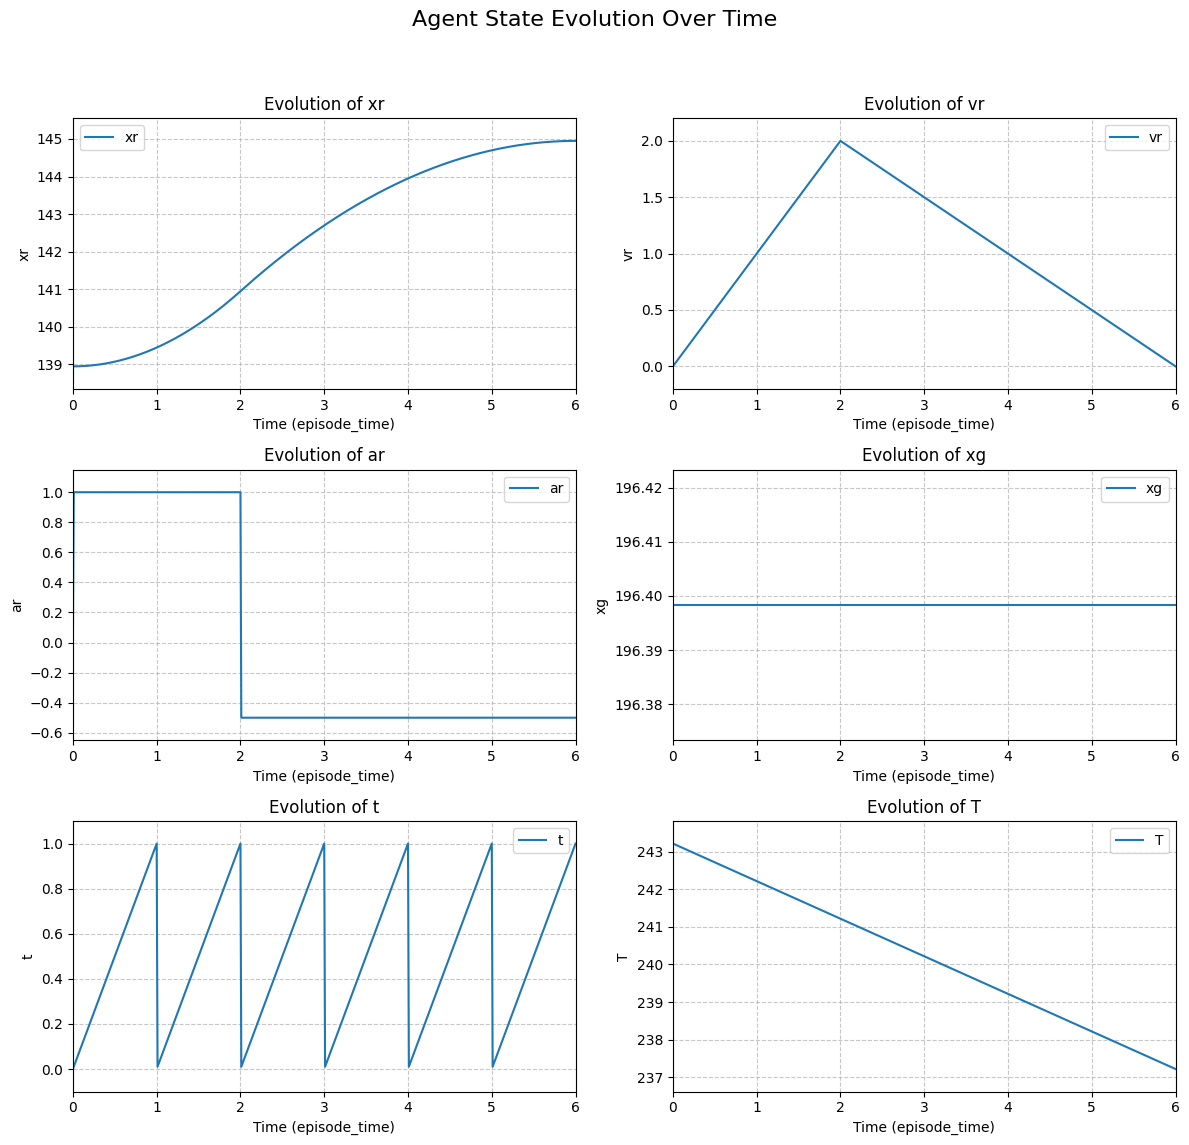

In [8]:
env.render(mode="matplotlib")